# 03 · Evaluation metrics: semantic and instance segmentation

**Goal:** understand how segmentation models are evaluated, pixel by pixel and object by object, by computing each metric **by hand** on small masks.

**Use case:** a self-driving car must understand its street view: which pixels are **road**, **sky** or **people** (semantic segmentation), and which pixels belong to **each individual pedestrian** (instance segmentation).

**Reminder:** segmentation outputs a **mask**: a grid the same size as the image, with a label for every pixel.
- **Semantic**: one label per **class** (all people share one label).
- **Instance**: one mask per **object** (person 1, person 2, person 3).

**Contents:** 1. The basics (binary masks) · 2. Semantic segmentation · 3. Instance segmentation · 4. Bonus: Panoptic Quality · 5. Summary

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from metrics import (binary_counts, pixel_accuracy, mask_iou, dice, confusion_matrix,
                     per_class_iou, mean_iou, match_predictions, average_precision,
                     ap_over_iou_thresholds, panoptic_quality)

os.makedirs("figures", exist_ok=True)
plt.rcParams["figure.dpi"] = 100

---
## 1. The basics: comparing two binary masks

**Positive** = object (1), **negative** = background (0). Each pixel lands in one box of the confusion matrix: **TP** (both say object), **FP** (the model colored too much), **FN** (the model missed it), **TN** (both say background).

Example: the model shifted the object one pixel to the right.

TP = 6   FP = 3   FN = 3   TN = 18


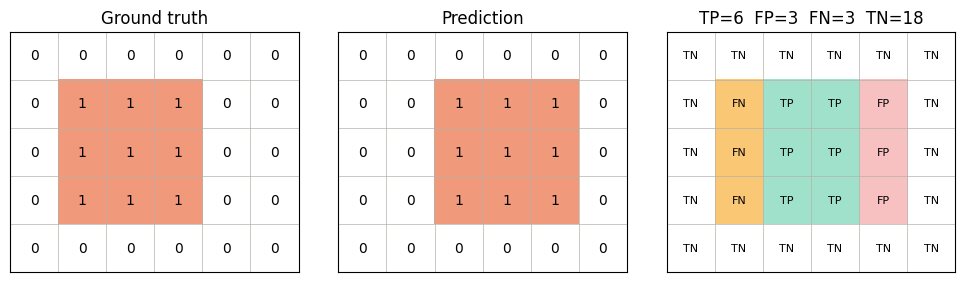

In [2]:
gt = np.zeros((5, 6), int);   gt[1:4, 1:4] = 1     # ground truth: 9 pixels
pred = np.zeros((5, 6), int); pred[1:4, 2:5] = 1   # prediction: 9 pixels, shifted right

tp, fp, fn, tn = binary_counts(gt.ravel(), pred.ravel())
print(f"TP = {tp}   FP = {fp}   FN = {fn}   TN = {tn}")

comparison = np.zeros_like(gt)
comparison[(gt == 1) & (pred == 1)] = 1; comparison[(gt == 0) & (pred == 1)] = 2; comparison[(gt == 1) & (pred == 0)] = 3
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
for ax, m, title in [(axes[0], gt, "Ground truth"), (axes[1], pred, "Prediction")]:
    ax.imshow(m, cmap=ListedColormap(["#FFFFFF", "#F0997B"]), vmin=0, vmax=1)
    for i in range(5):
        for j in range(6):
            ax.text(j, i, m[i, j], ha="center", va="center")
    ax.set_title(title)
axes[2].imshow(comparison, cmap=ListedColormap(["#FFFFFF", "#9FE1CB", "#F7C1C1", "#FAC775"]), vmin=0, vmax=3)
for i in range(5):
    for j in range(6):
        axes[2].text(j, i, ["TN", "TP", "FP", "FN"][comparison[i, j]], ha="center", va="center", fontsize=8)
axes[2].set_title(f"TP={tp}  FP={fp}  FN={fn}  TN={tn}")
for ax in axes:
    ax.set_xticks(np.arange(-.5, 6)); ax.set_yticks(np.arange(-.5, 5)); ax.set_xticklabels([]); ax.set_yticklabels([])
    ax.tick_params(length=0); ax.grid(color="#B4B2A9", lw=0.5)
plt.tight_layout()
plt.savefig("figures/03_binary_masks.png", dpi=150, bbox_inches="tight")
plt.show()

### 1.1 Pixel accuracy, IoU and Dice

| Metric | Formula | The logic |
|---|---|---|
| **Pixel accuracy** | (TP + TN) / total | Fraction of correct pixels. ⚠️ Fooled by the background |
| **IoU** | TP / (TP + FP + FN) | **Stack the masks**: shared area ÷ total area covered (shared counted once) |
| **Dice** | 2·TP / (2·TP + FP + FN) | **Masks side by side**: the shared area belongs to both masks, so it is counted twice. = F1 on pixels |

IoU and Dice **ignore TN**, so the background cannot fool them.

In [3]:
print(f"Pixel accuracy = {pixel_accuracy(gt, pred):.2f}")
print(f"IoU            = {mask_iou(gt, pred):.2f}   (6 shared / 12 covered)")
print(f"Dice           = {dice(gt, pred):.2f}   (2x6 shared / 9 + 9 pixels)")

lazy = np.zeros_like(gt)
print(f"\nLazy model (colors nothing): pixel accuracy = {pixel_accuracy(gt, lazy):.2f}, IoU = {mask_iou(gt, lazy):.2f}, Dice = {dice(gt, lazy):.2f}")

from sklearn.metrics import jaccard_score, f1_score
print(f"\nscikit-learn: IoU = {jaccard_score(gt.ravel(), pred.ravel()):.2f}, Dice = {f1_score(gt.ravel(), pred.ravel()):.2f}")

Pixel accuracy = 0.80
IoU            = 0.50   (6 shared / 12 covered)
Dice           = 0.67   (2x6 shared / 9 + 9 pixels)

Lazy model (colors nothing): pixel accuracy = 0.70, IoU = 0.00, Dice = 0.00

scikit-learn: IoU = 0.50, Dice = 0.67


**The lazy model finds nothing but still gets 70% pixel accuracy**, because most pixels are background. IoU and Dice correctly give 0.

**IoU vs. Dice:** Dice is always ≥ IoU (Dice = 2·IoU / (1 + IoU)), but they **always rank models in the same order**. Dice is the tradition in medical imaging; IoU is the standard elsewhere (COCO, Cityscapes).

In [4]:
for v in [0.10, 0.25, 0.50, 0.80, 1.00]:
    print(f"IoU = {v:.2f}  ->  Dice = {2 * v / (1 + v):.2f}")

IoU = 0.10  ->  Dice = 0.18
IoU = 0.25  ->  Dice = 0.40
IoU = 0.50  ->  Dice = 0.67
IoU = 0.80  ->  Dice = 0.89
IoU = 1.00  ->  Dice = 1.00


---
## 2. Semantic segmentation

Now each pixel has a **class**: sky, road or person. The confusion matrix becomes **N × N** (rows = truth, columns = prediction, diagonal = correct pixels).

Example: 100 pixels (50 sky, 40 road, 10 person).

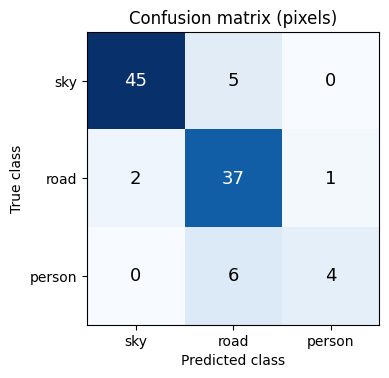

In [5]:
CLASSES = ["sky", "road", "person"]
cm = np.array([[45,  5, 0],    # real sky pixels
               [ 2, 37, 1],    # real road pixels
               [ 0,  6, 4]])   # real person pixels

fig, ax = plt.subplots(figsize=(4.2, 3.8))
ax.imshow(cm, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > 25 else "black", fontsize=13)
ax.set_xticks(range(3)); ax.set_xticklabels(CLASSES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title("Confusion matrix (pixels)")
plt.savefig("figures/03_semantic_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

**IoU per class:** each class takes its turn being "the positive". TP = diagonal, FN = rest of the **row**, FP = rest of the **column**.

**mIoU (mean IoU)** = the average of the per-class IoUs. Every class gets an **equal vote**, whatever its size. It is the standard metric for semantic segmentation (e.g. the Cityscapes benchmark).

In [6]:
ious = per_class_iou(cm)
for name, v in zip(CLASSES, ious):
    print(f"IoU {name:<7} = {v:.2f}")
print(f"\nmIoU           = {mean_iou(cm):.2f}")
print(f"Pixel accuracy = {np.trace(cm) / cm.sum():.2f}")

# Check with scikit-learn
y_true = np.concatenate([[i] * cm[i, j] for i in range(3) for j in range(3)]).astype(int)
y_pred = np.concatenate([[j] * cm[i, j] for i in range(3) for j in range(3)]).astype(int)
print("\nscikit-learn IoU per class:", np.round(jaccard_score(y_true, y_pred, average=None), 2))

IoU sky     = 0.87
IoU road    = 0.73
IoU person  = 0.36

mIoU           = 0.65
Pixel accuracy = 0.86

scikit-learn IoU per class: [0.87 0.73 0.36]


**What this shows:** pixel accuracy (0.86) looks good, but the model finds only 4 person pixels out of 10. **mIoU (0.65) reveals it**, because the "person" class counts for one third of the average even though people are only 10% of the pixels. For a self-driving car, that difference matters.

---
## 3. Instance segmentation

The model outputs **one mask per object**, each with a confidence score. It is evaluated **exactly like detection**, with **mask IoU** instead of box IoU:

**mask IoU** → TP / FP / FN → ranked list → **AP** → average over classes = **mask AP**

### 3.1 Two models, same pixels, different objects

Both models miss the heads of the pedestrians, but:
- **Model 1** separates the 3 pedestrians correctly.
- **Model 2** **merges pedestrians 1 and 2** into a single object.

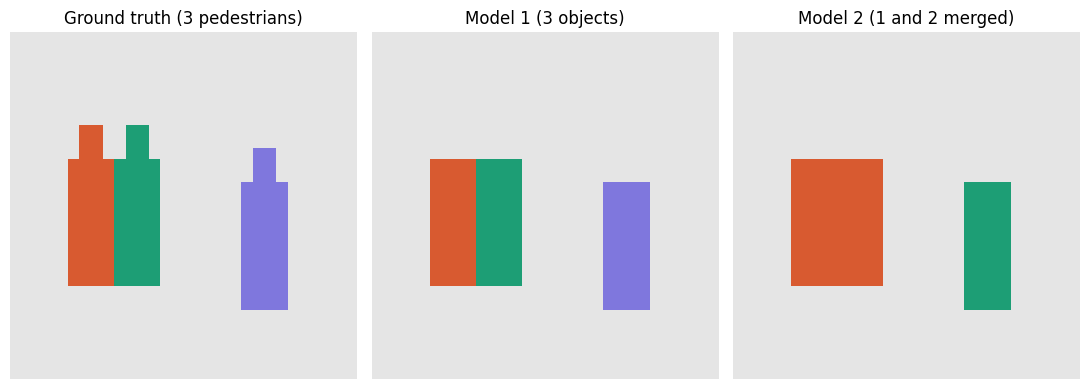

In [7]:
H, W = 30, 30
def person_mask(top, left):
    m = np.zeros((H, W), bool)
    m[top:top + 3, left + 1:left + 3] = True     # head
    m[top + 3:top + 14, left:left + 4] = True    # body
    return m

gt_masks = [person_mask(8, 5), person_mask(8, 9), person_mask(10, 20)]

def remove_head(mask):
    m = mask.copy(); top = np.where(m)[0].min(); m[top:top + 3] = False
    return m

model1 = [(remove_head(gt_masks[0]), 0.90), (remove_head(gt_masks[1]), 0.85), (remove_head(gt_masks[2]), 0.80)]
model2 = [(remove_head(gt_masks[0] | gt_masks[1]), 0.90), (remove_head(gt_masks[2]), 0.80)]   # 1 and 2 merged

def to_map(masks):
    out = np.zeros((H, W), int)
    for k, m in enumerate(masks, start=1):
        out[m] = k
    return out

cmap = ListedColormap(["#E5E5E5", "#D85A30", "#1D9E75", "#7F77DD"])
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, m, title in [(axes[0], to_map(gt_masks), "Ground truth (3 pedestrians)"),
                     (axes[1], to_map([m for m, _ in model1]), "Model 1 (3 objects)"),
                     (axes[2], to_map([m for m, _ in model2]), "Model 2 (1 and 2 merged)")]:
    ax.imshow(m, cmap=cmap, vmin=0, vmax=3); ax.set_title(title); ax.axis("off")
plt.tight_layout()
plt.savefig("figures/03_instance_models.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.2 A semantic metric cannot see the difference

In [8]:
gt_person = np.any(gt_masks, axis=0)
union1 = np.any([m for m, _ in model1], axis=0)
union2 = np.any([m for m, _ in model2], axis=0)
print("Same 'person' pixels in both models?", np.array_equal(union1, union2))
print(f"Semantic IoU of 'person': model 1 = {mask_iou(gt_person, union1):.2f}, model 2 = {mask_iou(gt_person, union2):.2f}")

Same 'person' pixels in both models? True
Semantic IoU of 'person': model 1 = 0.88, model 2 = 0.88


Same pixels, same score, yet model 2 thinks there are only 2 pedestrians.

### 3.3 Mask AP sees it

In [9]:
for name, model in [("Model 1", model1), ("Model 2", model2)]:
    rows = match_predictions(model, gt_masks, mask_iou, iou_threshold=0.5)
    print(f"--- {name} ---")
    for r in rows:
        res = f"TP (pedestrian {r['gt'] + 1})" if r["correct"] else "FP"
        print(f"  mask {r['index'] + 1}: confidence {r['score']:.2f}, best mask IoU {r['iou']:.2f} -> {res}")
    _, aps = ap_over_iou_thresholds(model, gt_masks, mask_iou)
    print(f"  mask AP@0.5 = {average_precision(rows, len(gt_masks)):.2f}   COCO mask AP@[0.5:0.95] = {np.mean(aps):.2f}\n")

--- Model 1 ---
  mask 1: confidence 0.90, best mask IoU 0.88 -> TP (pedestrian 1)
  mask 2: confidence 0.85, best mask IoU 0.88 -> TP (pedestrian 2)
  mask 3: confidence 0.80, best mask IoU 0.88 -> TP (pedestrian 3)
  mask AP@0.5 = 1.00   COCO mask AP@[0.5:0.95] = 0.80

--- Model 2 ---
  mask 1: confidence 0.90, best mask IoU 0.47 -> FP
  mask 2: confidence 0.80, best mask IoU 0.88 -> TP (pedestrian 3)
  mask AP@0.5 = 0.17   COCO mask AP@[0.5:0.95] = 0.13



Model 2's merged blob is twice the size of pedestrian 1, so its IoU is **below 0.5** → it counts as a **false positive**, and pedestrians 1 and 2 count as **missed**. Its AP falls from **1.00 to 0.17**.

(Model 1 is not perfect under COCO's strict thresholds: its masks miss the heads, so they fail at IoU 0.90 and 0.95.)

> **Key takeaway:** instance metrics check that **each object** was found **separately**. Semantic metrics only check pixels.

---
## 4. Bonus: Panoptic Quality (PQ)

**Panoptic segmentation** combines semantic ("stuff" like sky and road) and instance ("things" like people). Its metric splits the score in two:

$$\text{PQ} = \underbrace{\text{SQ}}_{\text{average IoU of matched objects}} \times \underbrace{\text{RQ}}_{\text{TP} / (\text{TP} + \frac{1}{2}\text{FP} + \frac{1}{2}\text{FN})}$$

- **SQ** (segmentation quality): how good are the shapes of the objects we matched?
- **RQ** (recognition quality): did we find the right objects?

In [10]:
for name, model in [("Model 1", model1), ("Model 2", model2)]:
    pq, sq, rq = panoptic_quality(model, gt_masks)
    print(f"{name}: SQ = {sq:.2f}   RQ = {rq:.2f}   PQ = {pq:.2f}")

Model 1: SQ = 0.88   RQ = 1.00   PQ = 0.88
Model 2: SQ = 0.88   RQ = 0.40   PQ = 0.35


Same SQ (the shapes they matched are equally good), but model 2's RQ is much lower: it failed to recognize two pedestrians. **PQ shows *why* a model is bad**, not just *that* it is bad.

---
## 5. Summary

| Task | Main metric(s) | What it checks | Our example |
|---|---|---|---|
| **Binary masks** | IoU, Dice | Overlap between predicted and true masks | Pixel acc. 0.80, IoU 0.50, Dice 0.67 |
| **Semantic** | mIoU | Is each pixel's class right? Every class gets an equal vote | Pixel acc. 0.86 but mIoU 0.65 |
| **Instance** | Mask AP (+ PQ) | Was each object found separately, with a good shape? | Same pixels: mask AP 1.00 vs. 0.17 |

> **Key takeaway:** IoU is the heart of segmentation metrics. Semantic segmentation averages it per class (mIoU); instance segmentation uses it to match objects, then applies the detection chain (mask AP).